# Chapitre 16 - Exercices 16.1 à 16.4

- **16.1** : générer exactement les données corrélées par blocs de la section 16.2.3 ;
- **16.2** : longueur d'arc $L_1$ d'un chemin de coefficients et monotonie ;
- **16.3** : les règles-feuilles d'un arbre reproduisent l'arbre (régression et
  régression logistique) ;
- **16.4** : programmer la simulation « lasso contre ridge » de la figure 16.2.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from esl.plotting import set_style, COLORS, BLUE, ORANGE, GRAY, SEQ, DIV, TWO_CLASS
set_style()

from esl.ch16_ensembles import (block_correlated_data, standardize, forward_stagewise,
                                l1_arc_length, logistic_irls, ridge_path_df)

## Exercice 16.1 : Données gaussiennes corrélées par blocs

**Énoncé (reformulé).** Décrire précisément comment engendrer les données corrélées
par blocs utilisées dans la simulation de la section 16.2.3 (figures 16.3 et 16.4).

Rappel du cahier des charges donné par le livre : un dictionnaire de $p=1000$
variables gaussiennes, fortement corrélées ($\rho=0{,}95$) à l'intérieur de blocs de
20 variables et non corrélées entre blocs ; un modèle vrai avec 50 coefficients non
nuls, **un par bloc**, tirés selon une loi normale centrée réduite ; un bruit gaussien
avec un rapport bruit/signal de $0{,}72$ ; $N=60$ observations.

### Rappels

- Un vecteur gaussien $X\in\mathbb R^p$ est entièrement déterminé par sa moyenne et sa
  matrice de covariance $\Sigma$. Si $Z\sim\mathcal N(0,I_q)$ et $A$ est une matrice
  $p\times q$, alors $AZ\sim\mathcal N(0,AA^T)$.
- Le **rapport bruit/signal** est $\mathrm{NSR}=\operatorname{Var}(\varepsilon)/\operatorname{Var}(f(X))$
  où $Y=f(X)+\varepsilon$.

### Solution

**1. La matrice de covariance visée.** Numérotons les blocs $b=1,\dots,50$ ; le bloc
$b$ contient les variables $j\in B_b=\{20(b-1)+1,\dots,20b\}$. On veut
$\operatorname{Var}X_j=1$ et
$$
\operatorname{Cov}(X_j,X_k)=\begin{cases}\rho&\text{si }j\neq k\text{ sont dans le même bloc},\\0&\text{sinon.}\end{cases}
$$
Ainsi $\Sigma$ est diagonale par blocs, chaque bloc valant
$\Sigma_0=(1-\rho)I_{20}+\rho\,\mathbf 1\mathbf 1^T$ (matrice à 1 sur la diagonale et
$\rho$ ailleurs).

**2. Une construction simple par facteur commun.** Tirons indépendamment
$Z_1,\dots,Z_{50}\sim\mathcal N(0,1)$ (un facteur par bloc) et
$E_1,\dots,E_{1000}\sim\mathcal N(0,1)$, puis posons, pour $j\in B_b$,
$$
X_j=\sqrt\rho\,Z_b+\sqrt{1-\rho}\,E_j .
$$
- $X_j$ est gaussienne comme combinaison linéaire de gaussiennes indépendantes ;
- $\operatorname{Var}X_j=\rho\operatorname{Var}Z_b+(1-\rho)\operatorname{Var}E_j=\rho+(1-\rho)=1$ (indépendance) ;
- pour $j\ne k$ dans le même bloc, par bilinéarité de la covariance et indépendance,
  $\operatorname{Cov}(X_j,X_k)=\rho\operatorname{Var}Z_b=\rho$ ;
- pour $j,k$ dans deux blocs différents, $X_j$ et $X_k$ ne font intervenir que des
  variables indépendantes : $\operatorname{Cov}(X_j,X_k)=0$.

On obtient donc exactement $X\sim\mathcal N(0,\Sigma)$. (On pourrait aussi utiliser la
factorisation de Cholesky $\Sigma_0=LL^T$ et poser $X_{B_b}=LZ^{(b)}$ ; la construction
par facteur commun est plus économique et plus parlante.)

**3. Les coefficients.** Pour chaque bloc $b$, on choisit **une** variable $j_b\in B_b$
(au hasard, uniformément) et l'on tire $\beta_{j_b}\sim\mathcal N(0,1)$ ; tous les
autres $\beta_j$ sont nuls. Le signal est $f(X)=\sum_b\beta_{j_b}X_{j_b}$.

**4. Le niveau de bruit.** Les $X_{j_b}$ appartiennent à des blocs différents : ils
sont indépendants et de variance 1, donc
$$
\operatorname{Var}f(X)=\sum_b\beta_{j_b}^2=\|\beta\|^2 .
$$
Pour obtenir $\mathrm{NSR}=0{,}72$, on prend $\varepsilon\sim\mathcal N(0,\sigma^2)$ avec
$\sigma^2=0{,}72\,\|\beta\|^2$, et $Y=f(X)+\varepsilon$.

**5. Échantillons.** On tire $N=60$ vecteurs $X$ i.i.d. pour l'apprentissage ; pour
l'échantillon test, on **garde le même $\beta$** (et le même $\sigma$) et on tire de
nouveaux $X$ et $\varepsilon$. Enfin, comme dans la figure 16.3, les variables sont
standardisées avant d'ajuster lasso et forward stagewise. Cette procédure est codée
dans `block_correlated_data` du module `esl/ch16_ensembles.py`.

### Vérification numérique

Avec un grand échantillon, la matrice de corrélation empirique doit être proche de
$\Sigma$. Regardons les 60 premières variables (3 blocs).

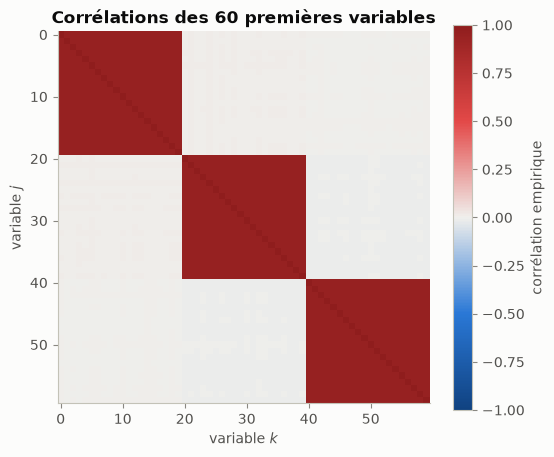

In [2]:
rng = np.random.RandomState(0)
X_big, y_big, beta, sigma = block_correlated_data(20000, rng=rng)
C = np.corrcoef(X_big[:, :60].T)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(C, cmap=DIV, vmin=-1, vmax=1)
fig.colorbar(im, ax=ax, label="corrélation empirique")
ax.set(title="Corrélations des 60 premières variables", xlabel="variable $k$",
       ylabel="variable $j$")
ax.grid(False)
plt.show()

In [3]:
same = np.kron(np.eye(3), np.ones((20, 20))).astype(bool) & ~np.eye(60, dtype=bool)
print("corrélation moyenne intra-bloc : %.3f" % C[same].mean())
print("corrélation moyenne inter-blocs : %.3f" % C[~np.kron(np.eye(3), np.ones((20, 20))).astype(bool)].mean())
print("un coefficient non nul par bloc :",
      np.all((beta.reshape(50, 20) != 0).sum(axis=1) == 1))
f_big = X_big @ beta
print("NSR empirique : %.3f (visé : 0,72)" % ((y_big - f_big).var() / f_big.var()))

corrélation moyenne intra-bloc : 0.950
corrélation moyenne inter-blocs : -0.001
un coefficient non nul par bloc : True
NSR empirique : 0.728 (visé : 0,72)


> **À retenir.** Des gaussiennes équicorrélées s'obtiennent par un **facteur commun** :
> $X_j=\sqrt\rho\,Z_b+\sqrt{1-\rho}\,E_j$. Le bruit se règle grâce à
> $\operatorname{Var}f(X)=\|\beta\|^2$, valable parce qu'il n'y a qu'un coefficient non
> nul par bloc.

## Exercice 16.2 : Longueur d'arc $L_1$ et monotonie

**Énoncé (reformulé).** Soit $\alpha:[0,T]\to\mathbb R^p$ un chemin de coefficients
continu, dérivable par morceaux, avec $\alpha(0)=0$. Sa **longueur d'arc $L_1$** entre
$0$ et $t$ est (éq. (16.16) du livre)
$$
\Lambda(t)=\int_0^t\|\dot\alpha(s)\|_1\,ds,\qquad \|v\|_1=\sum_{j=1}^p|v_j| .
$$
Montrer que $\Lambda(t)\ge\|\alpha(t)\|_1$, avec égalité si et seulement si $\alpha$ est
monotone sur $[0,t]$ (chaque coordonnée $\alpha_j$ est croissante ou décroissante).

### Rappels

- **Dérivable par morceaux** : il existe une subdivision $0=t_0<t_1<\dots<t_K=t$ telle
  que $\alpha$ soit de classe $C^1$ sur chaque $[t_{k-1},t_k]$.
- **Théorème fondamental de l'analyse** : si $g$ est $C^1$ sur $[a,b]$,
  $g(b)-g(a)=\int_a^bg'(s)\,ds$. En sommant sur les morceaux (et grâce à la
  continuité de $\alpha$ aux points $t_k$), on obtient pour chaque coordonnée
  $\alpha_j(t)=\alpha_j(0)+\int_0^t\dot\alpha_j(s)\,ds=\int_0^t\dot\alpha_j(s)\,ds$.
- **Inégalité triangulaire intégrale** : $\big|\int_0^tg\big|\le\int_0^t|g|$.

### Solution : l'inégalité

Fixons $t$ et une coordonnée $j$. D'après le théorème fondamental,
$$
|\alpha_j(t)|=\Big|\int_0^t\dot\alpha_j(s)\,ds\Big|\le\int_0^t|\dot\alpha_j(s)|\,ds .
$$
En sommant sur $j=1,\dots,p$ et par linéarité de l'intégrale,
$$
\|\alpha(t)\|_1=\sum_j|\alpha_j(t)|\le\sum_j\int_0^t|\dot\alpha_j(s)|\,ds=\int_0^t\sum_j|\dot\alpha_j(s)|\,ds=\Lambda(t).
$$

### Solution : le cas d'égalité

Une somme d'inégalités $a_j\le b_j$ est une égalité si et seulement si **chacune**
l'est. Il suffit donc d'étudier, pour $g=\dot\alpha_j$ (continue par morceaux), quand
$\big|\int_0^tg\big|=\int_0^t|g|$.

*Si $g$ garde un signe constant* (disons $g\ge0$ sur $[0,t]$, sauf peut-être en un
nombre fini de points), alors $|g|=g$ et l'égalité est évidente ; de même si $g\le0$.

*Réciproquement*, supposons l'égalité et, par exemple, $\int_0^tg\ge0$. Alors
$\int_0^t(|g|-g)=0$. La fonction $|g|-g$ est positive et continue sur chaque morceau ;
une fonction continue positive d'intégrale nulle sur un intervalle est nulle sur cet
intervalle. Donc $|g|=g$, c'est-à-dire $g\ge0$, sauf peut-être aux points de
raccordement. Le cas $\int_0^tg\le0$ donne de même $g\le0$.

Enfin, une fonction continue et $C^1$ par morceaux dont la dérivée est $\ge0$ (sauf en
un nombre fini de points) est croissante : sur chaque morceau, c'est le théorème des
accroissements finis, et on recolle par continuité. Ainsi :
$$
\Lambda(t)=\|\alpha(t)\|_1\iff\text{chaque }\alpha_j\text{ est monotone sur }[0,t].
$$
(Les coordonnées peuvent être monotones dans des sens différents : l'une croissante,
l'autre décroissante.)

> **Intuition.** $\Lambda(t)$ est la « distance parcourue » en norme $L_1$, $\|\alpha(t)\|_1$
> la distance « à vol d'oiseau » depuis l'origine. On ne parcourt pas plus que la
> distance à vol d'oiseau seulement si l'on ne revient jamais en arrière sur aucune
> coordonnée. C'est pourquoi les chemins monotones de $\mathrm{FS}_0$ (dans le
> dictionnaire augmenté $\mathcal T\cup\{-\mathcal T\}$, où les coefficients ne font que
> croître) vérifient $\Lambda=\|\alpha\|_1$ : décroître la perte le plus vite possible
> « par unité de longueur d'arc » ou « par unité de norme » y revient au même.

### Vérification numérique

Prenons le chemin $\alpha(t)=(\sin t,\ t/2,\ -t^2/10)$ sur $[0,2\pi]$ : seule la
première coordonnée n'est pas monotone (elle décroît à partir de $t=\pi/2$). La
fonction `l1_arc_length` calcule $\Lambda$ pour un chemin discrétisé (affine entre deux
instants, ce qui approche l'intégrale).

In [4]:
t = np.linspace(0, 2 * np.pi, 2001)
alpha = np.column_stack([np.sin(t), t / 2, -t ** 2 / 10])
Lam = l1_arc_length(alpha)
norm1 = np.abs(alpha).sum(axis=1)
# longueur d'arc exacte : int |cos| + t/2 + t^2/10
exact = np.where(t <= np.pi / 2, np.sin(t),
                 np.where(t <= 3 * np.pi / 2, 2 - np.sin(t), 4 + np.sin(t))) + t / 2 + t ** 2 / 10
print("écart maximal entre Lambda discrétisé et exact : %.1e" % np.abs(Lam - exact).max())

écart maximal entre Lambda discrétisé et exact : 8.9e-15


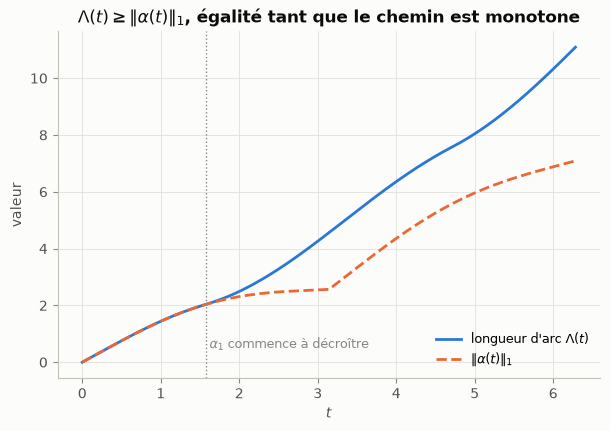

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, Lam, color=BLUE, label=r"longueur d'arc $\Lambda(t)$")
ax.plot(t, norm1, color=ORANGE, ls="--", label=r"$\|\alpha(t)\|_1$")
ax.axvline(np.pi / 2, color=GRAY, ls=":", lw=1)
ax.text(np.pi / 2 + 0.05, 0.5, r"$\alpha_1$ commence à décroître", color=GRAY, fontsize=9)
ax.set(title=r"$\Lambda(t)\geq\|\alpha(t)\|_1$, égalité tant que le chemin est monotone",
       xlabel="$t$", ylabel="valeur")
ax.legend()
plt.show()

Les deux courbes coïncident jusqu'à $t=\pi/2$, puis $\Lambda$ passe strictement
au-dessus. Appliquons maintenant le résultat aux chemins du lasso et du forward
stagewise sur les données prostate (cours 1, figure 16.1).

In [ ]:
from esl import datasets
from esl.ch16_ensembles import lasso_path_cd

df = datasets.load_prostate()
train = df[df["train"]]
names = [c for c in df.columns if c not in ("lpsa", "train")]
Xp, _, _ = standardize(train[names].to_numpy(float))
yp = train["lpsa"].to_numpy(float)
_, _, coef_lasso = lasso_path_cd(Xp, yp, n_lambdas=300, lambda_ratio=1e-4, tol=1e-10)
path_fs = forward_stagewise(Xp, yp - yp.mean(), eps=0.002, n_steps=1200)
for name, path in [("lasso", coef_lasso), ("forward stagewise", path_fs)]:
    print("%-18s Lambda final = %.3f, norme L1 finale = %.3f"
          % (name, l1_arc_length(path)[-1], np.abs(path[-1]).sum()))

Sur ces données (8 variables peu corrélées), les coefficients du lasso sont tous
monotones en fonction de $\lambda$ : la longueur d'arc est égale à la norme finale,
comme le prédit l'exercice. Le forward stagewise à pas fini $\varepsilon$ a une
longueur d'arc égale à $M\varepsilon$ ; elle dépasse la norme parce qu'une fois arrivé
près de la solution des moindres carrés, l'algorithme oscille (des pas $\pm\varepsilon$
qui se compensent).

> **À retenir.** $\Lambda(t)=\int_0^t\|\dot\alpha\|_1\ge\|\alpha(t)\|_1$ par l'inégalité
> triangulaire intégrale, avec égalité exactement pour les chemins monotones
> coordonnée par coordonnée.

## Exercice 16.3 : Les règles-feuilles reproduisent l'arbre

**Énoncé (reformulé).** On considère l'arbre de la figure 16.9 (coupure sur $X_1$ au
seuil $2{,}1$, puis, à droite, sur la variable qualitative $X_3\in\{S,M,L\}$, puis, pour
$X_3=S$, sur $X_7$ au seuil $4{,}5$) et les six règles (16.14) qui en découlent.
Montrer que la régression linéaire sur les règles $R_1,R_4,R_5,R_6$ donne le même
ajustement que l'arbre de régression correspondant. Montrer que c'est encore vrai en
classification si l'on ajuste une régression logistique.

### Rappels

Les règles (16.14) sont
$$
\begin{aligned}
R_1&=I(X_1<2{,}1), & R_2&=I(X_1\ge2{,}1),\\
R_3&=I(X_1\ge2{,}1)\,I(X_3=S), & R_4&=I(X_1\ge2{,}1)\,I(X_3\in\{M,L\}),\\
R_5&=I(X_1\ge2{,}1)\,I(X_3=S)\,I(X_7<4{,}5), & R_6&=I(X_1\ge2{,}1)\,I(X_3=S)\,I(X_7\ge4{,}5).
\end{aligned}
$$
Un **arbre de régression** partitionne l'espace en régions (feuilles)
$\mathcal R_1,\dots,\mathcal R_J$ et prédit dans chaque feuille la **moyenne** des $y_i$
qui y tombent (éq. (9.11)). Un **arbre de classification** estime dans chaque feuille la
proportion $\hat p_m$ d'observations de la classe 1 (éq. (9.16)) et prédit la classe
majoritaire.

### Solution : les quatre règles forment une partition

Les feuilles de l'arbre sont les nœuds 1, 4, 5 et 6, et $R_1,R_4,R_5,R_6$ sont
exactement leurs indicatrices. Vérifions que tout $x$ vérifie **une et une seule** de
ces règles :
- si $x_1<2{,}1$ : $R_1=1$ et les trois autres contiennent le facteur $I(x_1\ge2{,}1)=0$ ;
- si $x_1\ge2{,}1$ et $x_3\in\{M,L\}$ : $R_4=1$, $R_1=0$, et $R_5=R_6=0$ car $I(x_3=S)=0$ ;
- si $x_1\ge2{,}1$ et $x_3=S$ : $R_1=R_4=0$ et exactement l'une de $R_5,R_6$ vaut 1
  selon que $x_7<4{,}5$ ou non.

Donc $R_1+R_4+R_5+R_6=1$ et $R_kR_l=0$ pour $k\neq l$.

### Solution : régression linéaire

Notons $Z$ la matrice $N\times4$ dont les colonnes sont $R_1,R_4,R_5,R_6$ évaluées aux
$x_i$, et $N_m$ le nombre d'observations dans la feuille $m$ (supposé $>0$). Comme les
colonnes sont des indicatrices d'ensembles disjoints,
$$
Z^TZ=\operatorname{diag}(N_1,N_4,N_5,N_6),\qquad (Z^Ty)_m=\sum_{i\in\mathcal R_m}y_i .
$$
$Z^TZ$ est inversible (diagonale à termes $>0$), donc les moindres carrés
$\hat\alpha=(Z^TZ)^{-1}Z^Ty$ donnent $\hat\alpha_m=\frac1{N_m}\sum_{i\in\mathcal R_m}y_i=\bar y_m$.
La prédiction en un point $x$ de la feuille $m$ est
$\hat f(x)=\sum_l\hat\alpha_lR_l(x)=\hat\alpha_m=\bar y_m$ : c'est exactement la
prédiction de l'arbre.

> **Remarque.** Si l'on ajoute une constante au modèle, les colonnes deviennent liées
> ($R_1+R_4+R_5+R_6=1$) : les coefficients ne sont plus uniques, mais l'espace engendré
> par les colonnes est le même, donc la projection orthogonale de $y$ - l'ajustement -
> ne change pas. De même, ajouter $R_2=R_4+R_5+R_6$ et $R_3=R_5+R_6$ ne change rien :
> les six règles forment une famille **sur-complète** de rang 4.

### Solution : régression logistique

Avec $y_i\in\{0,1\}$ et le modèle $\operatorname{logit}P(Y=1\mid x)=\sum_l\alpha_lR_l(x)$,
un point de la feuille $m$ a pour probabilité $\sigma(\alpha_m)$ où
$\sigma(u)=1/(1+e^{-u})$. La log-vraisemblance (éq. (4.20)) s'écrit
$$
\ell(\alpha)=\sum_i\big[y_i\eta_i-\log(1+e^{\eta_i})\big]
=\sum_{m}\Big[\alpha_m\sum_{i\in\mathcal R_m}y_i-N_m\log(1+e^{\alpha_m})\Big],
$$
car $\eta_i=\alpha_m$ pour $i\in\mathcal R_m$. Elle se **sépare** en une fonction de
chaque $\alpha_m$.

Chaque terme est strictement concave en $\alpha_m$ (sa dérivée seconde vaut
$-N_m\sigma(\alpha_m)(1-\sigma(\alpha_m))<0$). On annule la dérivée :
$$
\frac{\partial\ell}{\partial\alpha_m}=\sum_{i\in\mathcal R_m}y_i-N_m\,\sigma(\alpha_m)=0
\iff\sigma(\hat\alpha_m)=\frac1{N_m}\sum_{i\in\mathcal R_m}y_i=\hat p_m .
$$
Si $0<\hat p_m<1$, $\hat\alpha_m=\log\frac{\hat p_m}{1-\hat p_m}$ : la probabilité ajustée
dans chaque feuille est la **proportion** de la classe 1, exactement l'estimation de
l'arbre de classification ; la classe prédite (seuil $1/2$) est donc la classe
majoritaire, comme pour l'arbre.

> **Remarque (feuilles pures).** Si $\hat p_m\in\{0,1\}$, la vraisemblance n'a pas de
> maximum fini : elle croît quand $\alpha_m\to\mp\infty$, et la probabilité ajustée tend
> vers $\hat p_m$. Le résultat reste vrai « à la limite ». Avec $K>2$ classes et une
> régression logistique multinomiale, le même calcul donne les proportions de chaque
> classe dans chaque feuille.

### Vérification numérique

Simulons des données avec $X_1\sim\mathcal U[0,5]$, $X_3$ qualitative uniforme sur
$\{S,M,L\}$ et $X_7\sim\mathcal U[0,10]$, puis construisons les six règles.

In [ ]:
rng = np.random.RandomState(0)
N = 500
x1 = 5 * rng.rand(N)
x3 = rng.choice(["S", "M", "L"], size=N)
x7 = 10 * rng.rand(N)
R = np.column_stack([
    x1 < 2.1,
    x1 >= 2.1,
    (x1 >= 2.1) & (x3 == "S"),
    (x1 >= 2.1) & (x3 != "S"),
    (x1 >= 2.1) & (x3 == "S") & (x7 < 4.5),
    (x1 >= 2.1) & (x3 == "S") & (x7 >= 4.5),
]).astype(float)
leaf_cols = [0, 3, 4, 5]                       # R1, R4, R5, R6
print("partition :", np.all(R[:, leaf_cols].sum(axis=1) == 1))
print("rang des 6 règles + constante :", np.linalg.matrix_rank(np.column_stack([np.ones(N), R])))

**Régression.** Une réponse quelconque (non constante par feuille), puis comparaison
entre l'ajustement linéaire sur $R_1,R_4,R_5,R_6$ et les moyennes par feuille.

In [ ]:
y = np.sin(x1) + 0.3 * x7 + (x3 == "M") + rng.randn(N)
Z = R[:, leaf_cols]
alpha_hat = np.linalg.lstsq(Z, y, rcond=None)[0]
leaf_id = Z.argmax(axis=1)
leaf_means = np.array([y[leaf_id == m].mean() for m in range(4)])
print("coefficients :", np.round(alpha_hat, 4))
print("moyennes     :", np.round(leaf_means, 4))
fit_all = np.column_stack([np.ones(N), R]) @ np.linalg.lstsq(np.column_stack([np.ones(N), R]), y, rcond=None)[0]
print("écart ajustement (6 règles + constante) / arbre : %.1e" % np.abs(fit_all - leaf_means[leaf_id]).max())

**Classification.** Réponse binaire, régression logistique par Newton–Raphson
(`logistic_irls`), comparée aux proportions par feuille.